# Exercises week 42

**October 12–16, 2026**

Date: **Deadline is Friday October 16 at midnight**


# Overarching aims of the exercises this week

The aim of the exercises this week is to compute the gradient of the neural
network you implemented last week, and then to train it.

To train neural networks we use gradient descent, since there is no
analytical expression for the optimal parameters. This means that you need
the gradient of the cost function with respect to the network parameters,
and then a gradient method. The gradient is computed with the
**backpropagation algorithm**, Section [8.8](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#backpropagation) of the
lecture notes, which Monday's lecture derived and which you now write by
hand. At every step you check your result against `jax.grad`, which does the
same computation for you.

You will begin by computing the gradient of a network with one layer, then
two layers, then any number of layers. Keeping track of the shapes and doing
things step by step will be very important this week.

Exercises 2–5 use the **single-vector convention** of exercises 1–4 of last
week: one input vector at a time, weights of shape (outputs, inputs) and
$z = Wx + b$. Exercise 6 switches to the **batched convention** of the lecture
notes (samples in rows, weights of shape (inputs, outputs), $Z = XW + b$,
Eq. (8.21)), which is what you need for Project 2. If you did not finish
last week's set, the full solution is in `exercisesweek41_solutions.ipynb`.

We recommend that you do the exercises by editing and running this notebook,
as it includes some checks along the way that you have implemented the
pieces correctly, and running small parts of the code at a time is important
for understanding the methods. If you cannot run the notebook locally, Google
Colab works as well, though we recommend that you set up VSCode (or
JupyterLab) and your Python environment to run code like this on your own
machine; ask on the course Discord or at the lab sessions if you have
trouble.

First, some setup code that you will need; don't change this cell. As last
week, the activation and cost functions are written with `jax.numpy`
(`jnp`) so that JAX can differentiate them. The derivatives `ReLU_der` and
`sigmoid_der` are the ones you will use in your own backpropagation.


In [49]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp                    # numpy-compatible functions that JAX can differentiate
from sklearn import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

np.random.seed(2026)   # so that your numbers can be compared with those of other students


# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)


# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)


def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def mse(predict, target):
    return jnp.mean((predict - target) ** 2)

# Exercise 1 - Understand the feed forward pass

**a)** Complete last week's exercises if you haven't already (recommended),
and compare with `exercisesweek41_solutions.ipynb`. In particular make sure
you understand the shapes of `W`, `b`, `z` and `a` in the two conventions
(single vector and batched), since every gradient below has the shape of the
parameter it belongs to.


# Exercise 2 - Gradient with one layer using JAX

For the first few exercises we will not use batched inputs. Only a single
input vector is passed through the layer at a time.

In this exercise you will compute the gradient of a single layer. You only
need to change the code in the cells right below an exercise; the rest works
out of the box. Feel free to make changes and see how things work, though!


**a)** If the weights and bias of a layer have shapes (10, 4) and (10,),
what will the shapes of the gradients of the cost function with respect to
these weights and this bias be?

*Answer:* The shape of the gradients of the cost function wrt. the weight and bias will be the same shape as the weights and bias. So the gradient of the weight will have shape (10, 4) and the gradient of the bias will have shape (10, ).


**b)** Complete the `feed_forward_one_layer` function. It should use the
sigmoid activation function. Also define the weight and bias with the
correct shapes.


In [91]:
def feed_forward_one_layer(W, b, x):
    z = W @ x + b
    a = sigmoid(z)
    return a


def cost_one_layer(W, b, x, target):
    predict = feed_forward_one_layer(W, b, x)
    return mse(predict, target)


x = np.random.rand(2)
target = np.random.rand(3)

W = np.random.normal(0, 1 / np.sqrt(2), (3, 2))
b = np.zeros(3) + 0.01

**c)** Compute the gradient of the cost function with respect to the weight
and bias by running the cell below. You will not need to change anything,
just make sure it runs by defining things correctly in the cell above.
`jax.grad(cost_one_layer, argnums=(0, 1))` returns a function that computes
the gradient of `cost_one_layer` with respect to its first two arguments,
`W` and `b`, by reverse-mode automatic differentiation — which for a neural
network *is* backpropagation (Section 4.14 of the lecture notes).


In [92]:
jax_one_layer = jax.grad(cost_one_layer, argnums=(0, 1))
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)

[[-0.00782056 -0.02029619]
 [ 0.00416502  0.01080921]
 [ 0.00561424  0.01457027]] [-0.07959846  0.042392    0.05714229]


# Exercise 3 - Gradient with one layer writing backpropagation by hand

Before you use the gradient you found using JAX, you will have to find the
gradient "manually", to better understand how the backpropagation
computation works. To do backpropagation "manually", you will need to write
out expressions for many derivatives along the computation. This is the
scalar/one-layer case of Section
[8.8.1](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#two-scalar-examples-no-hidden-layer-and-one-hidden-layer)
of the lecture notes, now with vectors.


We want to find the gradient of the cost function with respect to the weight
and bias. This is quite hard to do directly, so we instead use the chain rule
to combine multiple derivatives which are easier to compute.

$$
\frac{dC}{dW} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{dW}
$$

$$
\frac{dC}{db} = \frac{dC}{da}\frac{da}{dz}\frac{dz}{db}
$$


**a)** Which intermediary results can be reused between the two expressions?


C is the cost function which is a scalar, but $\bm{a}, \bm{z}$ and $\bm{b}$ are vectors whereas $\bm{W}$ is a matrix. We will thus mark them as bold. 

We see that between the two expressions, we can reuse $\frac{dC}{d\bm{a}} \frac{d\bm{a}}{d\bm{z}}$.  So this is the intermediary result that can be reused. Calculated it gives:

$$\frac{dC}{d\bm{a}} \frac{d\bm{a}}{d\bm{z}} = \frac{dC}{d\bm{a}} \sigma'(\bm{z}) =  \frac{dC}{d\bm{z}} = \bm{\delta}$$

**b)** What is the derivative of the cost with respect to the final
activation? You can use the JAX calculation to make sure you get the correct
result. Remember that we compute the *mean* in `mse`.


In [96]:
z = W @ x + b
a = sigmoid(z)

predict = a


def mse_der(predict, target):
    return 2.0*(predict - target)/predict.size     # the mean brings a factor 2/n

print('OWN', mse_der(predict, target))

cost_jax = jax.grad(mse, argnums=0)
print('JAX',cost_jax(predict, target))

OWN [-0.31946031  0.17453395  0.22951649]
JAX [-0.31946031  0.17453395  0.22951649]


**c)** What is the expression for the derivative of the sigmoid activation
function? You can use the JAX calculation to make sure you get the correct
result. (Since the sigmoid acts element by element, the gradient of
`sum(sigmoid(z))` with respect to `z` is exactly the element-wise derivative
$\sigma'(z)$; that is what the JAX line below computes.)


In [97]:
def sigmoid_der(z):
    s = sigmoid(z)
    return s*(1.0 - s)

print('OWN', sigmoid_der(z))

sigmoid_jax = jax.grad(lambda z: jnp.sum(sigmoid(z)))   # element-wise derivative of an element-wise function
print('JAX', sigmoid_jax(z))

OWN [0.24916541 0.24288685 0.24896814]
JAX [0.24916541 0.24288685 0.24896814]


**d)** Using the two derivatives you just computed, compute this
intermediary gradient you will use later (it is the *error* $\delta$ of the
layer, Eq. (8.60) of the lecture notes):

$$
\frac{dC}{dz} = \frac{dC}{da}\frac{da}{dz}
$$


In [98]:
dC_da = mse_der(a, target)
dC_dz = dC_da * sigmoid_der(z)

**e)** What is the derivative of the intermediary `z` with respect to the
weight and bias? What should the shapes be? The one for the weights is a
little tricky; it can be easier to play around in the next exercise first.
You can also try computing it with JAX to get a hint. (Lecture notes:
Eqs. (8.61)–(8.63), "the error is the bias gradient", and the outer product
with the layer input for the weights.)


We have:

$\bm{W}$= np.random.normal(0, 1 / np.sqrt(2), (3, 2)), so its shape is (3,2)

$\bm{b}$ = np.zeros(3) + 0.01, so its shape is (3,)

$\bm{x}$ = np.random.rand(2), so its shape is (2,)


Given:
$\bm{z} = \bm{Wx} + \bm{b}$
the shape is (3,2) @ (2,) + (3,) = (3,). So it has 3 entries

The derivative w.r.t weight:

$$\frac{d\bm{z}}{d\bm{W}} = \frac{dz_j}{dW_{ji}} = x_i$$

So $x_i$ is the answer at entry (j,j,i). Given the shape of $\bm{z}$ is (3,) and $\bm{W}$ is (3,2) we get that the shape of the derivative is (3,3,2)

The derivative w.r.t bias:

$$\frac{d\bm{z}}{d\bm{b}} = \bm{1}$$

Which is the identity matrix and has shape (3,3) as $\bm{z}$ has shape (3,) and $\bm{b}$ has shape (3,). 

**f)** Now combine the expressions you have worked with so far to compute
the gradients! Note that you always need to do a feed forward pass while
saving the `z`s and `a`s before you do backpropagation, as they are used in
the derivative expressions.


In [55]:
dC_da = mse_der(a, target)                
dC_dz = dC_da * sigmoid_der(z)             
dC_dW = np.outer(dC_dz, x)                 
dC_db = dC_dz 

print(dC_dW, dC_db)

[[-0.01462694 -0.02754146]
 [ 0.01663585  0.03132408]
 [-0.00325947 -0.00613735]] [-0.06668444  0.07584308 -0.01485998]


You should get the same results as with JAX.


In [56]:
W_g, b_g = jax_one_layer(W, b, x, target)
print(W_g, b_g)
print(np.allclose(dC_dW, W_g), np.allclose(dC_db, b_g))

[[-0.01462694 -0.02754146]
 [ 0.01663585  0.03132408]
 [-0.00325947 -0.00613735]] [-0.06668444  0.07584308 -0.01485998]
True True


# Exercise 4 - Gradient with two layers writing backpropagation by hand


Now that you have implemented backpropagation for one layer, you have found
most of the expressions you will need for more layers. Let's move up to two
layers (compare with the two-layer network of Section
[8.8.2](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#two-inputs-two-hidden-nodes-one-output) of the lecture
notes).


In [ ]:
x = np.random.rand(2)
target = np.random.rand(4)

W1 = np.random.rand(3, 2)
b1 = np.random.rand(3)

W2 = np.random.rand(4, 3)
b2 = np.random.rand(4)

layers = [(W1, b1), (W2, b2)]

In [58]:
z1 = W1 @ x + b1
a1 = sigmoid(z1)
z2 = W2 @ a1 + b2
a2 = sigmoid(z2)

We begin by computing the gradients of the last layer, as the gradients
must be propagated backwards from the end.

**a)** Compute the gradients of the last layer, just like you did for the
single layer in the previous exercise.


In [59]:
#Last layer
dC_da2 = mse_der(a2, target)
dC_dz2 = dC_da2 * sigmoid_der(z2)
dC_dW2 = np.outer(dC_dz2, a1)
dC_db2 = dC_dz2

To find the derivative of the cost with respect to the activation of the
first layer, we need a new expression, the one furthest to the right in the
following.

$$
\frac{dC}{da_1} = \frac{dC}{dz_2}\frac{dz_2}{da_1}
$$

**b)** What is the derivative of the second-layer intermediary with respect
to the first-layer activation? (First recall how you compute $z_2$.) This is
the step that *propagates the error backwards*, Eq. (8.64) of the lecture
notes.

$$
\frac{dz_2}{da_1}
$$


$\bm{z_2} = \bm{W}^2 \bm{a}_1 + \bm{b}_2$

Thus:

$$\frac{dz_2}{da_1} = \frac{d(\bm{\bm{W}^2 \bm{a}_1 + \bm{b}_2})}{d\bm{a_1}}= \bm{W}^2$$

**c)** Use this expression, together with expressions which are equivalent
to the ones for the last layer, to compute all the derivatives of the first
layer.

$$
\frac{dC}{dW_1} = \frac{dC}{da_1}\frac{da_1}{dz_1}\frac{dz_1}{dW_1}
$$

$$
\frac{dC}{db_1} = \frac{dC}{da_1}\frac{da_1}{dz_1}\frac{dz_1}{db_1}
$$


In [60]:
dC_da1 = W2.T @ dC_dz2
dC_dz1 = dC_da1 * sigmoid_der(z1)
dC_dW1 = np.outer(dC_dz1, x)
dC_db1 = dC_dz1

In [61]:
print(dC_dW1, dC_db1)
print(dC_dW2, dC_db2)

[[0.00122478 0.00230618]
 [0.00114618 0.00215818]
 [0.00044572 0.00083925]] [0.00558381 0.00522546 0.00203202]
[[-0.01625369 -0.01917604 -0.01377313]
 [ 0.03342819  0.03943845  0.02832654]
 [ 0.01732037  0.02043451  0.01467702]
 [-0.00455688 -0.00537619 -0.00386143]] [-0.02419709  0.04976502  0.02578508 -0.00678389]


**d)** Make sure you got the same gradient as the following code, which
uses JAX to do backpropagation. (`jax.grad` accepts a list of tuples of
arrays as the argument to differentiate and returns a gradient with the
same structure.)


In [62]:
def feed_forward_two_layers(layers, x):
    W1, b1 = layers[0]
    z1 = W1 @ x + b1
    a1 = sigmoid(z1)

    W2, b2 = layers[1]
    z2 = W2 @ a1 + b2
    a2 = sigmoid(z2)

    return a2

In [63]:
def cost_two_layers(layers, x, target):
    predict = feed_forward_two_layers(layers, x)
    return mse(predict, target)

grad_two_layers = jax.grad(cost_two_layers, argnums=0)
gradient = grad_two_layers(layers, x, target)
(W1_jax, b1_jax), (W2_jax, b2_jax) = gradient


print(W1_jax, b1_jax)
print(W2_jax, b2_jax)

#Check if they gave the same as in c
print(np.allclose(dC_dW1, W1_jax), np.allclose(dC_db1, b1_jax))
print(np.allclose(dC_dW2, W2_jax), np.allclose(dC_db2, b2_jax))

[[0.00122478 0.00230618]
 [0.00114618 0.00215818]
 [0.00044572 0.00083925]] [0.00558381 0.00522546 0.00203202]
[[-0.01625369 -0.01917604 -0.01377313]
 [ 0.03342819  0.03943845  0.02832654]
 [ 0.01732037  0.02043451  0.01467702]
 [-0.00455688 -0.00537619 -0.00386143]] [-0.02419709  0.04976502  0.02578508 -0.00678389]
True True
True True


**e)** How would you use the gradient from this layer to compute the
gradient of an even earlier layer? Would the expressions be any different?


The formula 

$$
\boxed{\;
  \delta_j^{l} = \left(\sum_k \delta_k^{l+1}w_{jk}^{l+1}\right)
                 f'\!\left(z_j^{l}\right),
  \qquad
  \bm{\delta}^{l} = \left(\bm{W}^{l+1}\bm{\delta}^{l+1}\right)
                    \circ f'\!\left(\bm{z}^{l}\right). \;}\tag{8.64}
$$

stays the same since l is the hidden layer. So when we want to go further backwards we do not need a new expression, but we just do the backward step one more time.

# Exercise 5 - Gradient with any number of layers writing backpropagation by hand


Well done on getting this far! Now it's time to compute the gradient with
any number of layers: the four equations of backpropagation, Section
[8.8.4](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-four-equations-of-backpropagation), and the
algorithm of Section [8.8.5](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter8.html#the-algorithm).

First, some code from the general neural network code from last week. Note
that we are still sending in one input vector at a time. We will change it to
use batched inputs later.


In [ ]:
def create_layers(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(layer_output_size, i_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers


def feed_forward(input, layers, activation_funcs):
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = W @ a + b
        a = activation_func(z)
    return a


def cost(layers, input, activation_funcs, target):
    predict = feed_forward(input, layers, activation_funcs)
    return mse(predict, target)

You might already have noticed a very important detail in backpropagation:
you need the values from the forward pass to compute all the gradients! The
feed forward function above is great for efficiency and for using JAX, as it
only cares about computing the final output, but now we need to also save
the results along the way.

Here is a function which does that for you.


In [65]:
def feed_forward_saver(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = W @ a + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a

**a)** Now complete the backpropagation function so that it returns the
gradient of the cost function with respect to all the weights and biases.
Use the JAX calculation below to make sure you get the correct answer.


In [66]:
def backpropagation(
    input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
):
    layer_inputs, zs, predict = feed_forward_saver(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            dC_da = cost_der(predict, target)
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = W.T @ dC_dz

        dC_dz = dC_da * activation_der(z)
        dC_dW = np.outer(dC_dz, layer_input)
        dC_db = dC_dz

        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads

In [ ]:
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

x = np.random.rand(network_input_size)
target = np.random.rand(4)

In [68]:
layer_grads = backpropagation(x, layers, activation_funcs, target, activation_ders)
print(layer_grads)

[(array([[ 0.01835982,  0.01566474],
       [-0.00790641, -0.00674581],
       [ 0.01155913,  0.00986234]]), Array([ 0.03195959, -0.01376296,  0.02012139], dtype=float64)), (array([[-0.0020327 , -0.00268908, -0.01151273],
       [-0.        , -0.        , -0.        ],
       [-0.01014689, -0.0134234 , -0.05746954],
       [ 0.01983896,  0.02624511,  0.11236311]]), Array([-0.01385487, -0.        , -0.06916109,  0.13522217], dtype=float64))]


In [21]:
cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, x, [sigmoid, ReLU], target)
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

[(Array([[ 0.00074771,  0.00116064],
       [-0.00033544, -0.00052068],
       [ 0.00044248,  0.00068684]], dtype=float64), Array([ 0.0069818 , -0.00313215,  0.00413167], dtype=float64)), (Array([[-0.01931988, -0.01787949, -0.01930115],
       [ 0.        ,  0.        ,  0.        ],
       [ 0.08850492,  0.08190643,  0.08841911],
       [ 0.        ,  0.        ,  0.        ]], dtype=float64), Array([-0.03903625,  0.        ,  0.17882615,  0.        ], dtype=float64))]
[(True, True), (True, True)]


# Exercise 6 - Batched inputs

Make new versions of all the functions in exercise 5 which now take batched
inputs instead. See last week's exercise 5 (and its solution) for details on
how to batch inputs to neural networks: samples in the rows of `inputs`,
weights of shape (inputs, outputs), `z = a @ W + b`. You will also need to
update the backpropagation function. Two things change there: the error is
propagated with `dC_dz @ W.T` instead of `W.T @ dC_dz`, and the gradients
of the weights and biases are *sums over the samples*,
`dC_dW = layer_input.T @ dC_dz` and `dC_db = np.sum(dC_dz, axis=0)` — compare
Eqs. (8.65)–(8.68) of the lecture notes written for a batch. Check your
batched backpropagation against `jax.grad` of the batched cost, as above.


In [69]:
np.random.seed(2026) #ran this cell multiple times so kept np.random.seed(2026) here

def create_layers_batch(network_input_size, layer_output_sizes, rng):
    """W of shape (inputs, outputs): samples in rows, Eq. (8.21)."""
    layers = []
    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = rng.normal(0, 1/np.sqrt(i_size), (i_size, layer_output_size))
        b = np.zeros(layer_output_size) + 0.01
        layers.append((W, b))
        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        a = activation_func(a @ W + b)
    return a


def cost_batch(layers, inputs, activation_funcs, targets):
    return mse(feed_forward_batch(inputs, layers, activation_funcs), targets)


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)
        zs.append(z)
    return layer_inputs, zs, a


def backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1:
            dC_da = cost_der(predict, targets)
        else:
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T                          # (n, M_{l+1}) @ (M_{l+1}, M_l)
        dC_dz = dC_da * activation_der(z)                # (n, M_l)
        dC_dW = layer_input.T @ dC_dz                    # (M_{l-1}, n) @ (n, M_l): summed over the samples
        dC_db = np.sum(dC_dz, axis=0)                    # (M_l,)
        layer_grads[i] = (dC_dW, dC_db)
    return layer_grads


n = 10
inputs = np.random.rand(n, 2)
targets = np.random.rand(n, 4)
layers_b = create_layers_batch(network_input_size, layer_output_sizes, np.random)

grads_b = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
grads_b_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)
print("shapes:", [(dW.shape, db.shape) for dW, db in grads_b])
print("agree with jax.grad:", [(np.allclose(dW, dW_j), np.allclose(db, db_j))
                                for (dW, db), (dW_j, db_j) in zip(grads_b, grads_b_jax)])

# the batched gradient is the average of the single-sample gradients (the cost is a mean over samples)
layers_t = [(W.T, b) for W, b in layers_b]               # the same network in the single-vector convention
single = [backpropagation(inputs[s], layers_t, activation_funcs, targets[s], activation_ders) for s in range(n)]
mean_dW1 = np.mean([g[0][0] for g in single], axis=0)

print('batch graident agrees with mean of single sample grad:', np.allclose(grads_b[0][0], mean_dW1.T))

shapes: [((2, 3), (3,)), ((3, 4), (4,))]
agree with jax.grad: [(True, True), (True, True)]
batch graident agrees with mean of single sample grad: True


# Exercise 7 - Training


**a)** Complete exercises 6 and 7 from last week (the iris data, softmax
output and cross entropy), but use your own backpropagation implementation
to compute the gradient.
- IMPORTANT: Do not implement the derivative terms for the softmax and the
  cross entropy separately, it will be very hard!
- Instead, use the fact that the derivatives multiplied together simplify to
  **prediction − target**: for the softmax output with the cross entropy the
  error of the last layer is $\delta^L = a^L - y$, Eq. (8.69) of the lecture
  notes (derived in Section [5.6](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter5.html) for the softmax; see also
  [this derivation](https://shivammehta25.github.io/posts/deriving-categorical-cross-entropy-and-softmax/)).
  In your `backpropagation` function this means that for the last layer you
  set `dC_dz = predict - target` directly, skipping `cost_der` and
  `activation_der`.

**b)** Use stochastic gradient descent with momentum when you train your
network (Sections [4.6 and 4.7](https://educationalmaterialuio.github.io/MachineLearningUiO/doc/LectureNotes/_build/html/chapter4.html) of the lecture notes; reuse
your Project 1 code). Call the learning rate `gamma`, as everywhere else in
the course, and compare the accuracy on a test set with that of the
full-batch gradient descent of last week.


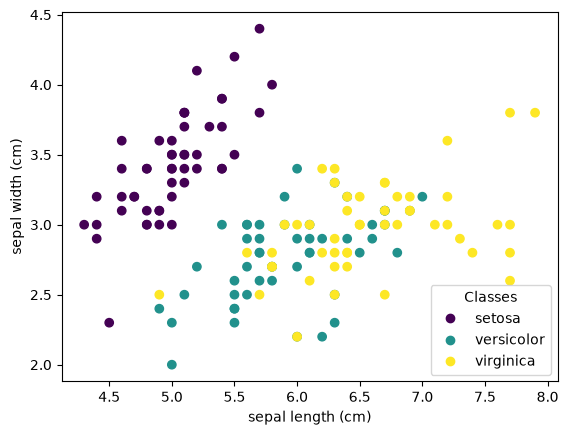

Accuracy untrained networks: 14.7%
shapes own: [((4, 8), (8,)), ((8, 3), (3,))]
shapes jax [((4, 8), (8,)), ((8, 3), (3,))]
agree with jax.grad: [(True, True), (True, True)]


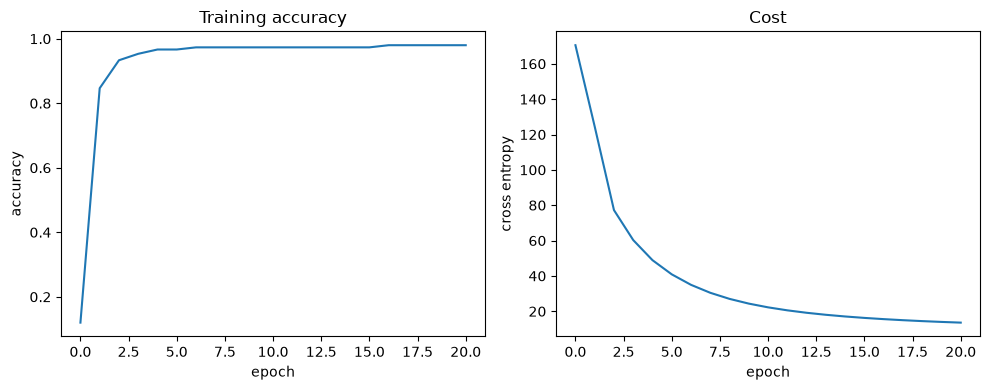

final accuracy: 0.98


In [78]:
""" Exercise 7a"""
np.random.seed(2026)

#Added softmax_ce to backpropagation_batch
def backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der, softmax_ce=False):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1:
            if softmax_ce:
                dC_dz = predict - targets                # last layer set this directly
            else:
                dC_dz = cost_der(predict, targets) * activation_der(z)
        else:
            (W, b) = layers[i + 1]
            dC_dz = (dC_dz @ W.T) * activation_der(z)    # (n, M_{l+1}) @ (M_{l+1}, M_l), Eq. (8.64)
        dC_dW = layer_input.T @ dC_dz                    # (M_{l-1}, n) @ (n, M_l): summed over the samples
        dC_db = np.sum(dC_dz, axis=0)                    # (M_l,)
        layer_grads[i] = (dC_dW, dC_db)
    return layer_grads

### Exercise 6 from previous week ###
def softmax(z):
    """Compute softmax values for each set of scores in the rows of the matrix z.
    Used with batched input data: one row of scores per sample."""
    e_z = jnp.exp(z - jnp.max(z, axis=1, keepdims=True))
    return e_z / jnp.sum(e_z, axis=1, keepdims=True)


def cross_entropy(predict, target):
    return jnp.sum(-target * jnp.log(predict))


# called cost_ce so it does not overwrite the MSE `cost` from exercise 5
def cost_ce(inputs, layers, activation_funcs, targets):
    predict = feed_forward_batch(inputs, layers, activation_funcs)
    return cross_entropy(predict, targets)


iris = datasets.load_iris()

_, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)
plt.show()

inputs = iris.data

# Since each prediction is a vector with a score for each of the three species,
# we make each target a vector with a 1 for the correct species and a 0 for the others (one-hot).
targets = np.zeros((len(iris.data), 3))
for i, t in enumerate(iris.target):
    targets[i, t] = 1


def accuracy(predictions, targets):
    one_hot_predictions = np.zeros(predictions.shape)

    for i, prediction in enumerate(predictions):
        one_hot_predictions[i, np.argmax(prediction)] = 1
    return accuracy_score(one_hot_predictions, targets)


network_input_size = 4
layer_output_sizes = [8, 3]
activation_funcs = [sigmoid, softmax]

#Small changes here from exercsie 6 from previouis week to solve this weeks task
activation_ders = [sigmoid_der, None]   #add derivatives of activation functions, none needed for softmax
layers = create_layers_batch(network_input_size, layer_output_sizes, np.random)
predictions = feed_forward_batch(inputs, layers, activation_funcs)
print(f"Accuracy untrained networks: {accuracy(predictions, targets):.1%}")

#set softmax_ce = True
grads_own = backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders, softmax_ce=True)
grads_jax = jax.grad(cost_ce, argnums=1)(inputs, layers, activation_funcs, targets) #argnums = 1 to get layers
#check own vs jax shapes
print("shapes own:", [(dW.shape, db.shape) for dW, db in grads_own]) 
print('shapes jax', [(dW.shape, db.shape) for dW, db in grads_jax]) 
print("agree with jax.grad:", [(np.allclose(dW, dW_j), np.allclose(db, db_j))
                                for (dW, db), (dW_j, db_j) in zip(grads_own, grads_jax)])

### Exercise 7 from previous week ###
def train_network(
    inputs, layers, activation_funcs, targets, activation_ders, gamma=0.001, epochs=1000):
    history = []

    for i in range(epochs):
        layers_grad = backpropagation_batch(inputs, layers, activation_funcs, targets, activation_ders, softmax_ce=True)
        layers = [(W - gamma * W_g, b - gamma * b_g) for (W, b), (W_g, b_g) in zip(layers, layers_grad)]

        if i % 50 == 0 or i == epochs - 1:
            predictions = feed_forward_batch(inputs, layers, activation_funcs)
            history.append((i, float(cost_ce(inputs, layers, activation_funcs, targets)), accuracy(predictions, targets)))

    return layers, history


layers_trained, history = train_network(inputs, layers, activation_funcs, targets, activation_ders, epochs = 1000)
epochs_rec, costs, accuracies = zip(*history)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(accuracies)
ax1.set(xlabel="epoch", ylabel="accuracy", title="Training accuracy")
ax2.plot(costs)
ax2.set(xlabel="epoch", ylabel="cross entropy", title="Cost")
plt.tight_layout()
plt.show()

print("final accuracy:", accuracies[-1])

Test accuracy, full-batch GD:      0.97
Test accuracy, SGD with momentum:  0.97


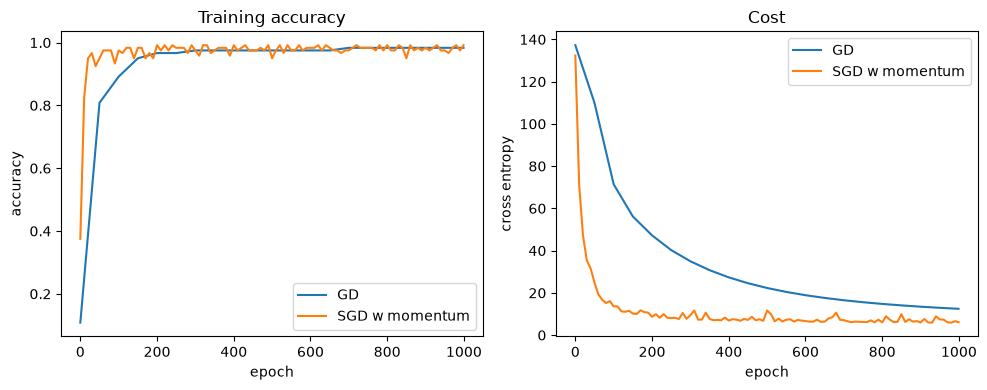

In [90]:
""" Exercise 7b """
from sklearn.model_selection import train_test_split

np.random.seed(2026)

# FUNCTIONS FROM PROJECT 1 
def optimiser(method, theta, g, state, t, gamma, beta=0.9, rho=0.99, beta1=0.9, beta2=0.999, eps=1e-8):
    if method == "plain":
        return theta - gamma * g, state
    if method == "momentum":
        v = beta * state.get("v", 0.0) + gamma * g               # Eq. (4.28)
        state["v"] = v
        return theta - v, state
    if method == "adagrad":
        r = state.get("r", 0.0) + g * g                           # Eq. (4.42)
        state["r"] = r
        return theta - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.45)
    if method == "rmsprop":
        r = rho * state.get("r", 0.0) + (1.0 - rho) * g * g       # Eq. (4.47)
        state["r"] = r
        return theta - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.48)
    if method == "adam":
        m = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g       # Eq. (4.51)
        r = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g   # Eq. (4.52)
        state["m"], state["r"] = m, r
        m_hat = m / (1.0 - beta1**t)                              # Eq. (4.54)
        r_hat = r / (1.0 - beta2**t)
        return theta - gamma * m_hat / (np.sqrt(r_hat) + eps), state   # Eq. (4.55)
    raise ValueError(f"unknown method {method}")

def make_batches(n, batch_size, rng):
    idx = rng.permutation(n)
    return [idx[i:i + batch_size] for i in range(0, n, batch_size)]

def step_length(t, t0, t1):
    return t0 / (t + t1)


def sgd_network(inputs, layers, activation_funcs, targets, activation_ders, method="plain",
                n_epochs=1000, batch_size=5, gamma=0.1, schedule=None, rng=np.random, **kw):
    """
    Minibatch SGD, Eq. (4.34), for neural networs based of project 1 function
    the minibatch gradient comes from backpropagation batch function, and the optimiser
    updates every W and b separately
    """
    n = inputs.shape[0]
    states = [({}, {}) for _ in layers]        # one state per W and per b (Project 1 had one theta)
    t, history = 0, []
    for epoch in range(n_epochs):
        for batch in make_batches(n, batch_size, rng):
            t += 1
            grads = backpropagation_batch(inputs[batch], layers, activation_funcs, targets[batch],
                                          activation_ders, softmax_ce=True)   # minibatch gradient
            g_t = gamma if schedule is None else step_length(t, *schedule)
            new_layers = []
            for (W, b), (gW, gb), (sW, sb) in zip(layers, grads, states):
                W, sW = optimiser(method, W, gW, sW, t, g_t, **kw)
                b, sb = optimiser(method, b, gb, sb, t, g_t, **kw)
                new_layers.append((W, b))
            layers = new_layers

        if epoch % 10 == 0 or epoch == n_epochs - 1:
            predictions = feed_forward_batch(inputs, layers, activation_funcs)
            history.append((epoch, float(cost_ce(inputs, layers, activation_funcs, targets)),
                            accuracy(predictions, targets)))
    return layers, history

#stratify to 20% of each species is taken for the test set instead of just 20% of all flowers
X_train, X_test, y_train, y_test = train_test_split(inputs, targets, test_size=0.2, stratify=iris.target, random_state=2026)

layers_7b = create_layers_batch(network_input_size, layer_output_sizes, np.random)
layers_gd, history_gd  = train_network(X_train, layers_7b, activation_funcs, y_train, activation_ders, epochs = 1000)
layers_sgd, history_sgd = sgd_network(X_train, layers_7b, activation_funcs, y_train, activation_ders, method='momentum', n_epochs=1000, gamma=0.001, beta=0.9)

acc_gd = accuracy(feed_forward_batch(X_test, layers_gd, activation_funcs), y_test)
acc_sgd = accuracy(feed_forward_batch(X_test, layers_sgd, activation_funcs), y_test)
print(f"Test accuracy, full-batch GD:      {acc_gd:.2f}")
print(f"Test accuracy, SGD with momentum:  {acc_sgd:.2f}")

#Plot graphs against each other to better compare 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

epochs_rec, costs, accuracies = zip(*history_gd)
ax1.plot(epochs_rec,accuracies, label='GD')
ax2.plot(epochs_rec, costs, label='GD')

epochs_rec, costs, accuracies = zip(*history_sgd)
ax1.plot(epochs_rec,accuracies, label='SGD w momentum')
ax2.plot(epochs_rec, costs, label='SGD w momentum')

ax1.set(xlabel="epoch", ylabel="accuracy", title="Training accuracy")
ax2.set(xlabel="epoch", ylabel="cross entropy", title="Cost")
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()


# Exercise 8 (Optional) - Object orientation

Passing in the layers, activation functions, activation derivatives and cost
derivatives into the functions each time leads to code which is easy to
understand in isolation, but messier when used in a larger context with data
splitting, data scaling, gradient methods and so forth. Creating an object
which stores these values can lead to code which is much easier to use, and
is what we recommend for Project 2.

**a)** Write a neural network class. You are free to implement it how you
see fit, though we strongly recommend not to save any input or output values
as class attributes, nor to let the neural network class handle gradient
methods internally. Gradient methods should be handled outside, by
performing general operations on the `layer_grads` list using functions or
classes separate from the neural network.

We provide here a skeleton structure which should get you started.


In [ ]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
    ):
        pass

    def predict(self, inputs):
        # Simple feed forward pass
        pass

    def cost(self, inputs, targets):
        pass

    def _feed_forward_saver(self, inputs):
        pass

    def compute_gradient(self, inputs, targets):
        pass

    def update_weights(self, layer_grads):
        pass

    # These last two methods are not needed in the project, but they can be nice to have!
    # The first one has a layers parameter so that you can use jax.grad on it.
    def jax_compliant_predict(self, layers, inputs):
        pass

    def jax_gradient(self, inputs, targets):
        pass

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2; the
right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| `W` has shape (10, 4) and `b` shape (10,). What are the shapes of $\partial C/\partial W$ and $\partial C/\partial b$? | The gradient of a scalar with respect to an array has the shape of that array: (10, 4) and (10,) — one number per parameter. |
| Which quantity is shared by $\partial C/\partial W$ and $\partial C/\partial b$ of the same layer? | The error $\delta = \partial C/\partial z = (\partial C/\partial a)\, f'(z)$; the bias gradient *is* $\delta$, the weight gradient is $\delta$ times the layer input (an outer product, Eqs. 8.61–8.63). |
| Why does `mse_der` carry a factor $2/n$? | Because `mse` takes the *mean*: $C = \frac1n\sum_i (a_i - y_i)^2$, so $\partial C/\partial a_i = \frac{2}{n}(a_i - y_i)$; forgetting the normalisation gives a gradient that is right up to a constant, which the learning rate then silently absorbs. |
| How does the error of layer $l+1$ become the error of layer $l$? | $\delta^{l} = (W^{l+1})^T \delta^{l+1} \odot f'(z^l)$ (Eq. 8.64): multiply by the transposed weights of the *next* layer and by the derivative of the activation of *this* layer. |
| Why must the forward pass save all the `z`s and `a`s? | Every derivative in the backward sweep is evaluated at the values of the forward pass: $f'(z^l)$ needs $z^l$ and the weight gradient needs the layer input $a^{l-1}$. |
| Why does the backward loop run from the last layer to the first? | The error of a layer depends on the error of the layer after it; the cost is only directly accessible at the output. |
| What changes in the batched version of backpropagation? | The error propagates as `dC_dz @ W.T` (samples stay in rows), and the parameter gradients are sums over the samples: `layer_input.T @ dC_dz` and `dC_dz.sum(axis=0)`. |
| With the softmax output and the cross entropy, what is $\delta^L$? | Simply $a^L - y$ (Eq. 8.69): the softmax Jacobian and the cross-entropy derivative cancel, which is why one never implements them separately. |
| `jax.grad` and your `backpropagation` agree to $10^{-15}$. What has JAX done? | Reverse-mode automatic differentiation of the forward pass: the same chain rule, in the same order, at the same cost of about two forward passes (Section 4.14). |
| Your network trains with full-batch gradient descent. Why switch to SGD with momentum? | One update per minibatch instead of per pass over the data, cheaper per step and with noise that helps escape flat regions; momentum damps the oscillations (Sections 4.6–4.7). |


### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 16 at midnight**. Collaboration is encouraged — list your
collaborators. The backpropagation code you write this week is the core of
Project 2 (deadline November 6).

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.


## Declaration of the use of LLMs

Tools used: Claude, model Opus 5.5 Medium.

- Exercise 3e: helped understanding shape of derivative w.r.t the weight.
- Exercise 6: helped with using np.random instead of rng which was used in tuesday seminar
- Exercise 7b: helped rewriting sgd function from Project 1 to sgd_networks so it works for neural networks. Specifically how to implement W and b instead of theta. Showed that we needed to implement stratify.

What was done without them: 
- Most of the code is was given in the tuesday seminar. Just tweaked it so it worked for our parameters instead of the shape used in tuesday seminar. 
- Markdown for written questions was done manually.
- Exercise 7 code was based on previously written code. 
